# Customer Support Tickets: SQL Analysis and Data Audit

**Goal:** use SQL to understand the work of a customer support team: how many tickets come in, how many get solved, and how satisfied customers are. Before answering, check whether the data can be trusted.

**Data:** Customer Support Ticket Dataset from Kaggle, 8,469 tickets, 17 columns. The values look generated (random text, evenly spread categories), so this is treated as a **practice dataset**, and the findings describe the data, not a real company.

**Tools:** SQL (SQLite) as the main tool, Python (pandas, numpy, matplotlib) for loading, charts and a significance test.

**Questions**
1. Can the time columns be used to measure response and resolution time?
2. How many tickets are solved, and does priority matter?
3. How satisfied are customers, and do channels, ticket types, priorities or products differ?
4. Are the differences real or just random noise?

## 1. Setup and loading data into SQL

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
BLUE, RED, GREY = "#2e86ab", "#d9534f", "#9aa5b1"

In [2]:
raw = pd.read_csv("../data/customer_support_tickets.csv")
print("Rows, columns:", raw.shape)

# Customer name and email are personal data and not needed for the analysis: drop them if present
df = raw.drop(columns=["Customer Name", "Customer Email"], errors="ignore")
df.columns = [c.lower().replace(" ", "_") for c in df.columns]
df = df.rename(columns={"customer_satisfaction_rating": "csat"})

# Dates as text in the format YYYY-MM-DD HH:MM:SS, so SQL can compare them
for col in ["first_response_time", "time_to_resolution"]:
    df[col] = pd.to_datetime(df[col]).dt.strftime("%Y-%m-%d %H:%M:%S")

# Age bands are calculated in pandas to keep the SQL simple
df["age_band"] = pd.cut(df["customer_age"], bins=[17, 25, 35, 45, 55, 70],
                        labels=["18-25", "26-35", "36-45", "46-55", "56-70"]).astype(str)

conn = sqlite3.connect(":memory:")
df.to_sql("tickets", conn, index=False)

def q(sql):
    return pd.read_sql_query(sql, conn)

print("Columns in the SQL table:")
print(", ".join(df.columns))

Rows, columns: (8469, 15)
Columns in the SQL table:
ticket_id, customer_age, customer_gender, product_purchased, date_of_purchase, ticket_type, ticket_subject, ticket_description, ticket_status, resolution, ticket_priority, ticket_channel, first_response_time, time_to_resolution, csat, age_band


## 2. Data audit

A support analysis usually starts with response time and resolution time. Before calculating them, the time columns have to be checked.

In [3]:
# Q1. Which columns are filled for each ticket status?
sql = """
SELECT ticket_status,
       COUNT(*)                                   AS tickets,
       SUM(first_response_time IS NOT NULL)       AS with_first_response,
       SUM(time_to_resolution IS NOT NULL)        AS with_resolution,
       SUM(csat IS NOT NULL)                      AS with_csat
FROM tickets
GROUP BY ticket_status
ORDER BY tickets DESC;
"""
res = q(sql)
print(res.to_string(index=False))

            ticket_status  tickets  with_first_response  with_resolution  with_csat
Pending Customer Response     2881                 2881                0          0
                     Open     2819                    0                0          0
                   Closed     2769                 2769             2769       2769


In [4]:
# Q2. Are the time columns consistent? (closed tickets)
sql = """
SELECT COUNT(*)                                          AS closed_tickets,
       SUM(time_to_resolution < first_response_time)     AS resolved_before_first_response,
       ROUND(100.0 * SUM(time_to_resolution < first_response_time) / COUNT(*), 1) AS pct
FROM tickets
WHERE ticket_status = 'Closed';
"""
res = q(sql)
print(res.to_string(index=False))

 closed_tickets  resolved_before_first_response   pct
           2769                            1365 49.30


In [5]:
# Q3. Time span of the timestamps
sql = """
SELECT MIN(first_response_time) AS earliest_response,
       MAX(first_response_time) AS latest_response,
       MIN(time_to_resolution)  AS earliest_resolution,
       MAX(time_to_resolution)  AS latest_resolution
FROM tickets;
"""
res = q(sql)
print(res.to_string(index=False))

  earliest_response     latest_response earliest_resolution   latest_resolution
2023-05-31 21:55:39 2023-06-02 00:54:21 2023-05-31 21:53:30 2023-06-02 00:55:33


In [6]:
# Q4. Is the ticket text usable?
sql = """
SELECT COUNT(*) AS tickets,
       SUM(ticket_description LIKE '%{product_purchased}%') AS description_with_unfilled_placeholder
FROM tickets;
"""
res = q(sql)
print(res.to_string(index=False))

 tickets  description_with_unfilled_placeholder
    8469                                   8469


**Audit result**
- There is **no ticket creation time**. `First Response Time` and `Time to Resolution` are single timestamps, not durations, so response time cannot be calculated.
- The timestamps are **not consistent**: for about half of the closed tickets the resolution time is earlier than the first response. All timestamps fall within about two days.
- Every ticket description contains an unfilled template placeholder, so the text is not useful for analysis.
- Ratings (`csat`) and resolution exist **only for closed tickets**.

**Decision:** response time and resolution time are **not analysed**, because the numbers would be wrong. The analysis uses ticket volume, status, priority, channel, product and customer satisfaction.

## 3. Ticket volume

In [7]:
# Q5. Tickets by type with share of total (window function)
sql = """
SELECT ticket_type,
       COUNT(*) AS tickets,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS share_pct
FROM tickets
GROUP BY ticket_type
ORDER BY tickets DESC;
"""
res = q(sql)
print(res.to_string(index=False))

         ticket_type  tickets  share_pct
      Refund request     1752      20.70
     Technical issue     1747      20.60
Cancellation request     1695      20.00
     Product inquiry     1641      19.40
     Billing inquiry     1634      19.30


In [8]:
# Q6. Tickets by channel with share of total
sql = """
SELECT ticket_channel,
       COUNT(*) AS tickets,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS share_pct
FROM tickets
GROUP BY ticket_channel
ORDER BY tickets DESC;
"""
res = q(sql)
print(res.to_string(index=False))

ticket_channel  tickets  share_pct
         Email     2143      25.30
         Phone     2132      25.20
  Social media     2121      25.00
          Chat     2073      24.50


In [9]:
# Q7. Most frequent product for each ticket type (CTE + RANK)
sql = """
WITH counts AS (
    SELECT ticket_type, product_purchased, COUNT(*) AS tickets
    FROM tickets
    GROUP BY ticket_type, product_purchased
),
ranked AS (
    SELECT *, RANK() OVER (PARTITION BY ticket_type ORDER BY tickets DESC) AS rnk
    FROM counts
)
SELECT ticket_type, product_purchased, tickets
FROM ranked
WHERE rnk = 1
ORDER BY ticket_type;
"""
res = q(sql)
print(res.to_string(index=False))

         ticket_type         product_purchased  tickets
     Billing inquiry             Apple AirPods       55
Cancellation request               LG Smart TV       53
Cancellation request Microsoft Xbox Controller       53
     Product inquiry                 Canon EOS       52
      Refund request          Sony PlayStation       52
      Refund request               Sony Xperia       52
     Technical issue                GoPro Hero       57


## 4. Solved tickets and backlog

            ticket_status  tickets  share_pct
Pending Customer Response     2881      34.00
                     Open     2819      33.30
                   Closed     2769      32.70


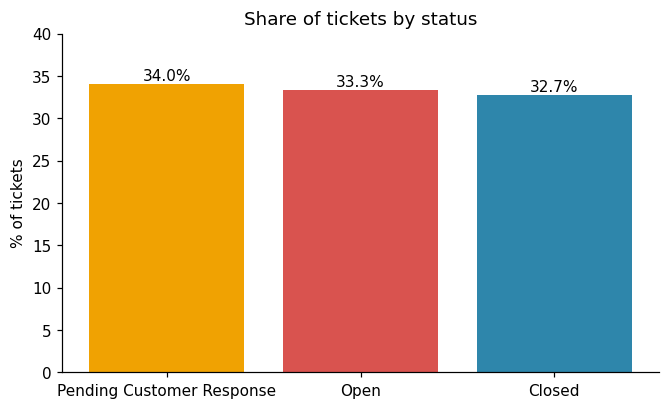

In [10]:
# Q8. Ticket status
sql = """
SELECT ticket_status,
       COUNT(*) AS tickets,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS share_pct
FROM tickets
GROUP BY ticket_status
ORDER BY tickets DESC;
"""
res = q(sql)
print(res.to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4))
colors = {"Closed": BLUE, "Open": RED, "Pending Customer Response": "#f0a202"}
ax.bar(res["ticket_status"], res["share_pct"], color=[colors[s] for s in res["ticket_status"]])
for i, v in enumerate(res["share_pct"]):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
ax.set_title("Share of tickets by status")
ax.set_ylabel("% of tickets")
ax.set_ylim(0, max(res["share_pct"]) + 6)
plt.savefig("../images/01_ticket_status.png", bbox_inches="tight")
plt.show()

ticket_priority  tickets  closed  closed_pct
       Critical     2129     726       34.10
           High     2085     705       33.80
         Medium     2192     694       31.70
            Low     2063     644       31.20


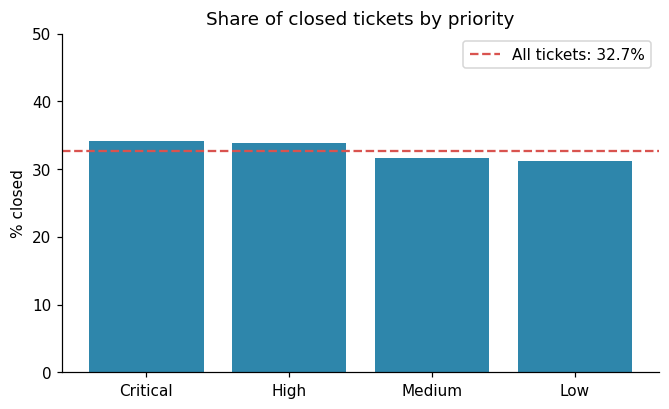

In [11]:
# Q9. Share of closed tickets by priority
sql = """
SELECT ticket_priority,
       COUNT(*) AS tickets,
       SUM(ticket_status = 'Closed') AS closed,
       ROUND(100.0 * SUM(ticket_status = 'Closed') / COUNT(*), 1) AS closed_pct
FROM tickets
GROUP BY ticket_priority
ORDER BY CASE ticket_priority
             WHEN 'Critical' THEN 1 WHEN 'High' THEN 2
             WHEN 'Medium' THEN 3 ELSE 4 END;
"""
res = q(sql)
print(res.to_string(index=False))
overall_closed = (df["ticket_status"] == "Closed").mean() * 100
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(res["ticket_priority"], res["closed_pct"], color=BLUE)
ax.axhline(overall_closed, color=RED, linestyle="--", label=f"All tickets: {overall_closed:.1f}%")
ax.set_title("Share of closed tickets by priority")
ax.set_ylabel("% closed")
ax.set_ylim(0, 50)
ax.legend()
plt.savefig("../images/02_closed_by_priority.png", bbox_inches="tight")
plt.show()

## 5. Customer satisfaction (CSAT)

Ratings from 1 (worst) to 5 (best) exist only for **closed tickets**, so all satisfaction figures describe closed tickets only.

In [12]:
# Q10. Overall satisfaction
sql = """
SELECT COUNT(csat)                                   AS rated_tickets,
       ROUND(AVG(csat), 2)                           AS avg_rating,
       ROUND(100.0 * SUM(csat >= 4) / COUNT(csat), 1) AS satisfied_pct,
       ROUND(100.0 * SUM(csat <= 2) / COUNT(csat), 1) AS dissatisfied_pct
FROM tickets
WHERE csat IS NOT NULL;
"""
res = q(sql)
print(res.to_string(index=False))

 rated_tickets  avg_rating  satisfied_pct  dissatisfied_pct
          2769        2.99          39.30             39.80


In [13]:
# Q11. Rating distribution
sql = """
SELECT CAST(csat AS INT) AS rating,
       COUNT(*) AS tickets,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS share_pct
FROM tickets
WHERE csat IS NOT NULL
GROUP BY rating
ORDER BY rating;
"""
res = q(sql)
print(res.to_string(index=False))

 rating  tickets  share_pct
      1      553      20.00
      2      549      19.80
      3      580      20.90
      4      543      19.60
      5      544      19.60


ticket_channel  rated  avg_rating  satisfied_pct
          Chat    674        3.08          41.50
  Social media    684        2.97          37.40
         Email    720        2.96          39.60
         Phone    691        2.95          38.50
The intervals overlap, so the channels cannot be told apart.


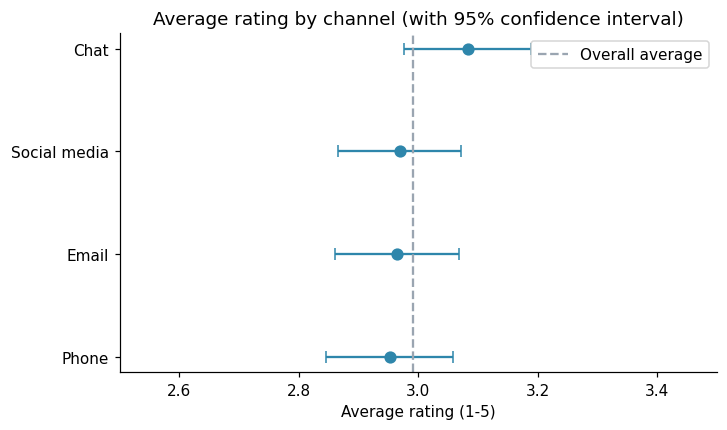

In [14]:
# Q12. Satisfaction by channel
sql = """
SELECT ticket_channel,
       COUNT(csat)                                    AS rated,
       ROUND(AVG(csat), 2)                            AS avg_rating,
       ROUND(100.0 * SUM(csat >= 4) / COUNT(csat), 1) AS satisfied_pct
FROM tickets
WHERE csat IS NOT NULL
GROUP BY ticket_channel
ORDER BY avg_rating DESC;
"""
res = q(sql)
print(res.to_string(index=False))
rows = q("SELECT ticket_channel, csat FROM tickets WHERE csat IS NOT NULL")
stats = rows.groupby("ticket_channel")["csat"].agg(["mean", "std", "count"])
stats["ci"] = 1.96 * stats["std"] / np.sqrt(stats["count"])
stats = stats.sort_values("mean")

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(stats["mean"], stats.index, xerr=stats["ci"], fmt="o", color=BLUE,
            capsize=4, markersize=7)
ax.axvline(rows["csat"].mean(), color=GREY, linestyle="--", label="Overall average")
ax.set_xlim(2.5, 3.5)
ax.set_title("Average rating by channel (with 95% confidence interval)")
ax.set_xlabel("Average rating (1-5)")
ax.legend()
plt.savefig("../images/03_csat_by_channel.png", bbox_inches="tight")
plt.show()
print("The intervals overlap, so the channels cannot be told apart.")

In [15]:
# Q13. Satisfaction by ticket type
sql = """
SELECT ticket_type,
       COUNT(csat)                                    AS rated,
       ROUND(AVG(csat), 2)                            AS avg_rating,
       ROUND(100.0 * SUM(csat >= 4) / COUNT(csat), 1) AS satisfied_pct
FROM tickets
WHERE csat IS NOT NULL
GROUP BY ticket_type
ORDER BY avg_rating DESC;
"""
res = q(sql)
print(res.to_string(index=False))

         ticket_type  rated  avg_rating  satisfied_pct
Cancellation request    516        3.03          40.10
     Billing inquiry    544        3.03          41.70
     Product inquiry    533        3.02          39.80
     Technical issue    580        2.96          37.10
      Refund request    596        2.93          37.90


In [16]:
# Q14. Satisfaction by priority
sql = """
SELECT ticket_priority,
       COUNT(csat)         AS rated,
       ROUND(AVG(csat), 2) AS avg_rating
FROM tickets
WHERE csat IS NOT NULL
GROUP BY ticket_priority
ORDER BY avg_rating DESC;
"""
res = q(sql)
print(res.to_string(index=False))

ticket_priority  rated  avg_rating
            Low    644        3.05
         Medium    694        2.98
           High    705        2.98
       Critical    726        2.96


In [17]:
# Q15. Satisfaction by customer age band
sql = """
SELECT age_band,
       COUNT(csat)         AS rated,
       ROUND(AVG(csat), 2) AS avg_rating
FROM tickets
WHERE csat IS NOT NULL
GROUP BY age_band
ORDER BY age_band;
"""
res = q(sql)
print(res.to_string(index=False))

age_band  rated  avg_rating
   18-25    390        2.96
   26-35    515        3.05
   36-45    532        2.98
   46-55    542        2.98
   56-70    790        2.98


In [18]:
# Q16. Best and worst products by average rating (at least 40 rated tickets)
sql = """
WITH product_scores AS (
    SELECT product_purchased,
           COUNT(csat)         AS rated,
           ROUND(AVG(csat), 2) AS avg_rating
    FROM tickets
    WHERE csat IS NOT NULL
    GROUP BY product_purchased
    HAVING COUNT(csat) >= 40
),
ranked AS (
    SELECT *,
           RANK() OVER (ORDER BY avg_rating DESC) AS best_rank,
           RANK() OVER (ORDER BY avg_rating ASC)  AS worst_rank
    FROM product_scores
)
SELECT product_purchased, rated, avg_rating,
       CASE WHEN best_rank <= 3 THEN 'highest' ELSE 'lowest' END AS group_name
FROM ranked
WHERE best_rank <= 3 OR worst_rank <= 3
ORDER BY avg_rating DESC;
"""
res = q(sql)
print(res.to_string(index=False))

      product_purchased  rated  avg_rating group_name
   Dyson Vacuum Cleaner     59        3.22    highest
           Google Pixel     69        3.22    highest
      Garmin Forerunner     70        3.21    highest
               Dell XPS     48        2.75     lowest
    GoPro Action Camera     59        2.75     lowest
            Sony Xperia     78        2.69     lowest
Fitbit Versa Smartwatch     63        2.54     lowest


## 6. Are the differences real or just noise?

Some channels, types and products have a slightly higher average rating than others. With random ratings between 1 and 5, some groups will always look better than others by chance. A **permutation test** checks this: the ratings are shuffled randomly 5,000 times, and for each shuffle the gap between the best and the worst group is recorded. If the real gap is typical for shuffled data, the difference is probably noise.

In [19]:
rated = q('''
SELECT ticket_channel, ticket_type, ticket_priority, age_band, product_purchased, csat
FROM tickets WHERE csat IS NOT NULL
''')
rng = np.random.default_rng(42)
values = rated["csat"].to_numpy()

def gap(codes, vals, n_groups):
    means = np.bincount(codes, weights=vals, minlength=n_groups) / np.bincount(codes, minlength=n_groups)
    return means.max() - means.min()

results = []
for col in ["ticket_channel", "ticket_type", "ticket_priority", "age_band", "product_purchased"]:
    codes, uniques = pd.factorize(rated[col])
    k = len(uniques)
    observed = gap(codes, values, k)
    null = np.array([gap(codes, rng.permutation(values), k) for _ in range(5000)])
    p_value = (null >= observed).mean()
    results.append({"Group by": col, "Groups": k, "Best minus worst": observed,
                    "Typical gap if random": np.median(null), "p-value": p_value})

perm = pd.DataFrame(results)
print(perm.round(3).to_string(index=False))

         Group by  Groups  Best minus worst  Typical gap if random  p-value
   ticket_channel       4              0.13                   0.10     0.30
      ticket_type       5              0.10                   0.14     0.80
  ticket_priority       4              0.09                   0.11     0.60
         age_band       5              0.08                   0.14     0.87
product_purchased      42              0.68                   0.76     0.75


Products: 42
Products outside the 95% range: 1 (about 2.1 are expected by pure chance)


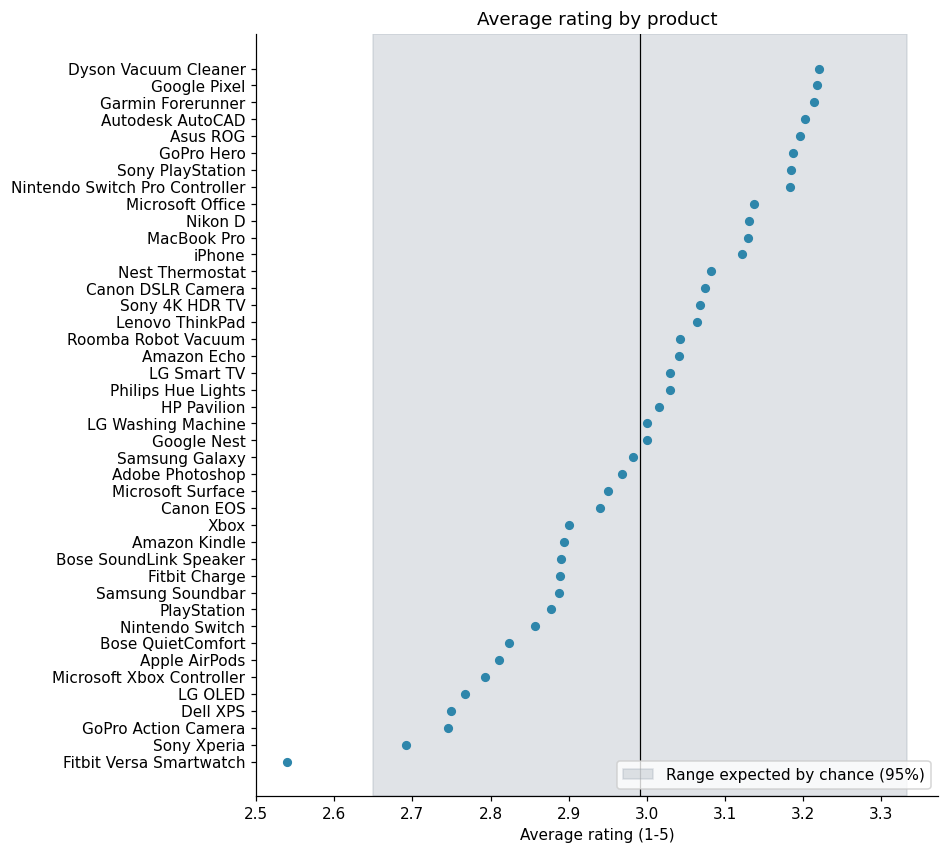

In [20]:
# Products: how many look 'unusual' just by chance?
overall_mean, overall_sd = values.mean(), values.std(ddof=1)
prod = rated.groupby("product_purchased")["csat"].agg(["mean", "count"])
prod["z"] = (prod["mean"] - overall_mean) / (overall_sd / np.sqrt(prod["count"]))
outside = (prod["z"].abs() > 1.96).sum()
print(f"Products: {len(prod)}")
print(f"Products outside the 95% range: {outside} "
      f"(about {0.05 * len(prod):.1f} are expected by pure chance)")

prod = prod.sort_values("mean")
se_typical = overall_sd / np.sqrt(prod["count"].median())

fig, ax = plt.subplots(figsize=(8, 9))
ax.axvspan(overall_mean - 1.96 * se_typical, overall_mean + 1.96 * se_typical,
           color=GREY, alpha=0.3, label="Range expected by chance (95%)")
ax.scatter(prod["mean"], prod.index, color=BLUE, s=25, zorder=3)
ax.axvline(overall_mean, color="black", linewidth=0.8)
ax.set_title("Average rating by product")
ax.set_xlabel("Average rating (1-5)")
ax.legend(loc="lower right")
plt.savefig("../images/04_csat_by_product.png", bbox_inches="tight")
plt.show()

## 7. Conclusions and recommendations

**What the data shows**
- **Volume is evenly spread:** the 8,469 tickets split almost equally between 5 ticket types (19-21% each) and 4 channels (about 25% each). No single problem or channel dominates.
- **Large backlog:** only **32.7%** of tickets are closed; 33.3% are open and 34.0% wait for the customer's response. Critical tickets are closed only slightly more often (34.1%) than low-priority ones (31.2%).
- **Satisfaction is neutral:** the average rating of closed tickets is **2.99 out of 5**. 39.3% of customers are satisfied (4-5) and 39.8% are dissatisfied (1-2). Each rating from 1 to 5 appears in about 20% of tickets.
- **No real differences between groups:** the gaps between channels, ticket types, priorities and age bands are the same size as shuffled random data (p-values from 0.30 to 0.87). Of 42 products, 1 is outside the range expected by chance, and about 2 would be expected anyway. The lowest-rated product (Fitbit Versa Smartwatch, 2.54) is not proof of a product problem.

**Recommendations for the support team**
1. **Fix data collection first:** store the ticket creation time and the first response and resolution timestamps in a consistent way. Without them, response time and SLA cannot be measured.
2. **Work on the backlog:** two thirds of tickets are not closed. Check how critical and high-priority tickets are assigned, because their closing rate is almost the same as for low-priority tickets.
3. **Do not act on small rating differences** between channels, products or age groups. They are not statistically reliable.
4. **Collect ratings for more tickets:** ratings exist only for closed tickets, so the picture of satisfaction is incomplete.

**Limitations**
- The dataset looks synthetic (random text, evenly spread values), so the findings describe this dataset and not a real company. The value of the project is the method: auditing the data, using SQL for the analysis, and testing whether differences are real.
- Closing rates by priority were compared without a significance test, and the differences are small.